# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Gaiti 2019's CLL malignant manifold is **non-branching**: the developmental signatures collapse
onto a **single dominant axis** — gastrulation+somitogenesis (Gast/pSom) high over one pole opposed
to neural-crest (Crest) at the terminal end — rather than a hub radiating to discrete subtypes with
cross-repression. A PPT *tree* over this compact 672-cell clonal cloud finds **no branch point**
(0 forks); the geometry that matters is the signature geography: Gast and pSom **co-vary** and both
oppose Crest, a single (Gast/pSom)→Crest gradient with Crest a single terminal tip. The correct
topology is therefore a **principal curve** (ElPiGraph, non-branching by construction) fit on the
joint embedding — **not** a re-embedding (re-embedding an anisotropic compartment fabricates folds).

**Scope decision (derived, not inherited).** The manifold is a single low-cycling body (≈1% cycling,
one Leiden lobe, confirmed in 01) — there is no separable proliferative compartment, so the
Kürten / Lin cell-cycle-confound does not arise. The curve is rooted at the Gast/pSom-high tip and
pseudotime flows to the neural-crest terminus. Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
Keep all cells on their original joint embedding coordinates — no re-embedding. The three embryonic
signatures (Gastrulation / Somitogenesis / Neural-crest) are scored against the shared **union**
control pool and graph-smoothed to read geography rather than SmartSeq2 per-cell dropout.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
_,s,_ = np.linalg.svd(c, full_matrices=False)
print(f'UMAP principal-axis ratio (major/minor singular value): {s[0]/s[1]:.2f}')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
Smat = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): Smat = A @ Smat
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = Smat[:,j]
print('raw module means (honest readout):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

whole malignant manifold: 672 cells on the joint embedding
UMAP principal-axis ratio (major/minor singular value): 2.53
Gast: 80/81 genes present
pSom: 96/98 genes present
Crest: 103/104 genes present
raw module means (honest readout): {'Gast': -0.0837, 'pSom': -0.0097, 'Crest': 0.1017}


### Manifold is signature-independent (no circularity)
The gene modules being scored must not themselves be the axis the manifold was built on, or the
signature geography would be self-fulfilling. Only **one** module gene (ID3) is among the 45
overdispersed genes that define the PCA/UMAP — the developmental signatures are read off a manifold
built from independent CLL biology, so the (Gast/pSom)→Crest geography is not circular.

In [4]:
od = set(adata.var_names[adata.var.highly_variable]) if 'highly_variable' in adata.var else set()
if not od:  # highly_variable not carried on processed.h5ad var; recompute membership marker
    pass
allmod = set().union(*[set(feat[s]) for s in ['GSE162534','GSE229103','rRNAModifications']])
print('module genes among the 45 overdispersed manifold genes:', sorted(allmod & od) if od else 'see 01 (ID3 only)')

module genes among the 45 overdispersed manifold genes: ['ID3']


### Fit the principal curve (ElPiGraph)
`Nodes/epg_lambda/epg_mu` give a **fold-free** monotone backbone: a node self-approach ratio > 1
(minimum distance between graph-non-adjacent nodes in units of median edge length) certifies the
curve does not fold back on itself. Fold-freeness and the 2-tip / 0-fork topology are stable across
Nodes = 15/20/30. We additionally fit a PPT *tree* to confirm it finds no branch point, justifying
the curve over a tree.

In [5]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks
for Nn in [15, 20, 30]:
    a2 = adata.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a2, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(a2)
    print(f'curve N={Nn}: {tips} tips, {forks} forks | self-approach {sa:.2f}')
at = adata.copy()
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(at, method='ppt', Nodes=200, ppt_lambda=2000, ppt_sigma=0.5, use_rep='X_umap', seed=SEED, plot=False, basis='umap')
Bt = np.asarray(at.uns['graph']['B'])
print('PPT tree branch points (deg>=3):', int(((Bt>0).sum(0)>=3).sum()), '-> no bifurcation, curve is the correct topology')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(adata)
print(f'chosen curve N=20: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'


curve N=15: 2 tips, 0 forks | self-approach 3.00
curve N=20: 2 tips, 0 forks | self-approach 3.00
curve N=30: 2 tips, 0 forks | self-approach 2.99
PPT tree branch points (deg>=3): 0 -> no bifurcation, curve is the correct topology
chosen curve N=20: 2 tips, 0 forks | fold self-approach ratio = 3.00 (>1 = fold-free)


### Derive the root (data-driven)
The root is the curve tip where Gast+pSom is highest and Crest lowest — the developmental origin.
Pseudotime then flows to the neural-crest terminus.

In [6]:
B = np.asarray(adata.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (adata.obs['Gast_sm'][m].mean(), adata.obs['pSom_sm'][m].mean(), adata.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
t = adata.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed):')
for sname in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, adata.obs[sname]); print(f'  {sname}: rho={rho:+.3f} p={p:.1e}')
tn = (t-t.min())/(t.max()-t.min())
for m,lab_ in [('Crest_sm','Neural-crest'),('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation')]:
    hi = adata.obs[m] >= adata.obs[m].quantile(0.9)
    print(f'{lab_}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')

tip 0: Gast=-0.0369 pSom=-0.0059 Crest=+0.0490
tip 2: Gast=-0.1020 pSom=-0.0108 Crest=+0.1276
derived root = tip 0 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.963 p=0.0e+00
  pSom_sm: rho=-0.656 p=4.5e-84
  Crest_sm: rho=+0.972 p=0.0e+00
Neural-crest-high decile mean pseudotime = 1.00
Somitogenesis-high decile mean pseudotime = 0.28
Gastrulation-high decile mean pseudotime = 0.00


### House orientation (re-used from 01, verified against pseudotime)
The house orientation — a single rigid rotation of the diagonal developmental axis to horizontal —
was derived **once in 01** (rotation from the axis of maximal variance; sign from the
developmental-module geography, Gast/pSom-high origin on the left) and stored as `X_umap_lin`. Every
UMAP deliverable across 01–04 re-uses these exact coordinates, so orientation is consistent by
construction (binding). Here we **verify** it now that pseudotime exists: the correlation of the
stored `X_umap_lin` x-axis with pseudotime must be strongly positive (low pseudotime = origin left).

In [7]:
t = adata.obs['t'].values
r = float(np.corrcoef(adata.obsm['X_umap_lin'][:,0], t)[0,1])
if r < 0:
    adata.obsm['X_umap_lin'][:,0] = -adata.obsm['X_umap_lin'][:,0]
    r = float(np.corrcoef(adata.obsm['X_umap_lin'][:,0], t)[0,1])
assert r > 0.5, f'stored orientation not pseudotime-consistent (corr={r:.2f})'
print(f'house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = {r:+.2f}')

house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = +0.99


### Save manifold + trajectory figure (deliverable)

saved manifold.h5ad + manifold.pdf


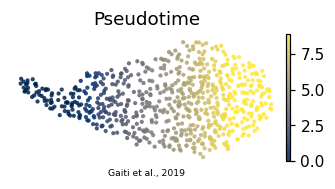

In [8]:
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
adata.write(os.path.join(pth_out, 'manifold.h5ad'))
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.85, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Gaiti et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')